الرجاء رفع الملفات 


Saving gh_top_1000_projects_vulns.jsonl to gh_top_1000_projects_vulns (3).jsonl
 جاري معالجة الملف: gh_top_1000_projects_vulns (3).jsonl
هل تريد رفع ملف آخر؟  yes


Saving dataset.jsonl to dataset (4).jsonl
 جاري معالجة الملف: dataset (4).jsonl
هل تريد رفع ملف آخر؟  yes


Saving cvefixes_clean (1).csv to cvefixes_clean (1) (1).csv
 جاري معالجة الملف: cvefixes_clean (1) (1).csv
هل تريد رفع ملف آخر؟  no

 إجمالي عدد الدوال المجمعة من كل الملفات: 5133
عدد الأكواد الآمنة (0): 4358
عدد الأكواد المصابة (1): 775

  تدريب وتقييم نموذج: Random Forest 
                precision    recall  f1-score   support

    Secure (0)       0.93      1.00      0.97       872
Vulnerable (1)       0.99      0.61      0.75       155

      accuracy                           0.94      1027
     macro avg       0.96      0.80      0.86      1027
  weighted avg       0.94      0.94      0.93      1027



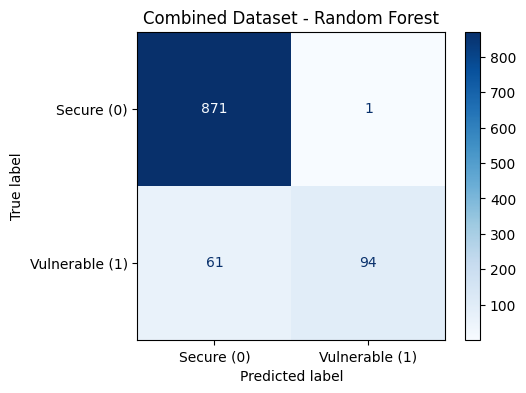


  تدريب وتقييم نموذج: XGBoost 
                precision    recall  f1-score   support

    Secure (0)       0.95      0.99      0.97       872
Vulnerable (1)       0.91      0.72      0.81       155

      accuracy                           0.95      1027
     macro avg       0.93      0.85      0.89      1027
  weighted avg       0.95      0.95      0.94      1027



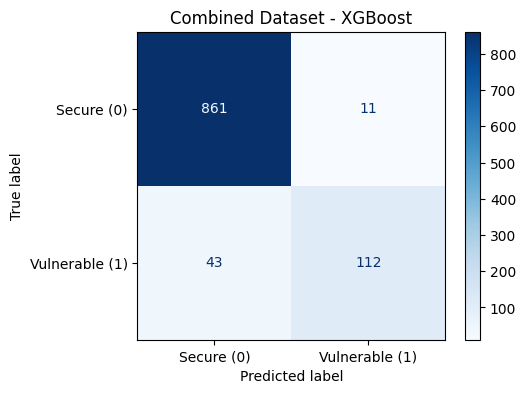


  تدريب وتقييم نموذج: Logistic Regression 
                precision    recall  f1-score   support

    Secure (0)       0.96      0.93      0.94       872
Vulnerable (1)       0.66      0.75      0.71       155

      accuracy                           0.91      1027
     macro avg       0.81      0.84      0.83      1027
  weighted avg       0.91      0.91      0.91      1027



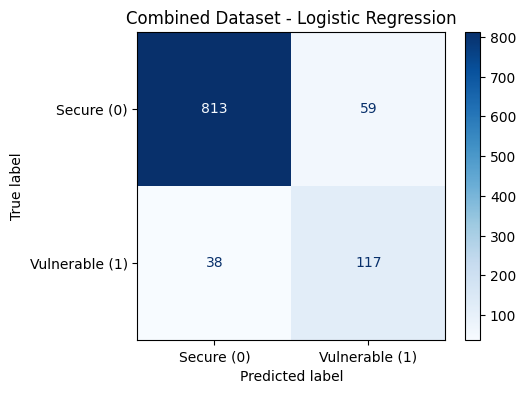

In [12]:
from google.colab import files
import csv
import json
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

all_codes = []
all_labels = []

print("الرجاء رفع الملفات ")

while True:
    try:
        uploaded = files.upload()
        if not uploaded:
            break
        for fname, content in uploaded.items():
            print(f" جاري معالجة الملف: {fname}")

            if fname.endswith('.csv'):
                with open(fname, newline="", encoding="utf-8") as f:
                    reader = csv.DictReader(f)
                    for row in reader:
                        try:
                            code_val = next((v for v in row.values() if v and len(str(v)) > 15), None)

                            label_val = next((v for v in row.values() if str(v).strip().lower() in ["0", "1", "true", "false", "secure", "vulnerable", "buggy", "insecure"]), None)

                            if code_val:
                                all_codes.append(str(code_val))
                                lbl = 1 if label_val and str(label_val).lower() in ["1", "true", "vulnerable", "buggy", "insecure"] else 0
                                all_labels.append(lbl)
                        except:
                            continue
            elif fname.endswith(('.json', '.jsonl')):
                with open(fname, "r", encoding="utf-8") as f:
                    try:
                        first_char = f.read(1)
                        f.seek(0)
                        if first_char == '[':
                            items = json.load(f)
                        else:
                            items = [json.loads(line) for line in f if line.strip()]

                        for item in items:
                            if isinstance(item, dict):
                                text_fields = {k: str(v) for k, v in item.items() if isinstance(v, str) and len(v) > 15}
                                if text_fields:
                                    best_code_key = max(text_fields, key=lambda k: len(text_fields[k]))
                                    code_val = text_fields[best_code_key]

                                    lbl = None
                                    for k, v in item.items():
                                        val_str = str(v).strip().lower()
                                        if val_str in ["1", "true", "vulnerable", "buggy", "insecure"] or (isinstance(v, int) and v > 0):
                                            lbl = 1
                                            break
                                        elif val_str in ["0", "false", "secure", "safe"]:
                                            lbl = 0
                                            break

                                    if lbl is None:
                                        if "vuln" in fname.lower() or "bug" in fname.lower():
                                            lbl = 1
                                        else:
                                            lbl = 0

                                    all_codes.append(code_val)
                                    all_labels.append(lbl)
                    except Exception as e:
                        print(f"خطأ في قراءة الملف: {e}")

        cont = input("هل تريد رفع ملف آخر؟  ")
        if cont.lower() != 'yes':
            break
    except Exception as e:
        print("انتهى الرفع أو حدث خطأ:", e)
        break

print(f"\n إجمالي عدد الدوال المجمعة من كل الملفات: {len(all_codes)}")
print(f"عدد الأكواد الآمنة (0): {all_labels.count(0)}")
print(f"عدد الأكواد المصابة (1): {all_labels.count(1)}")

if len(set(all_labels)) < 2:
    print(" تنبيه: البيانات لا تحتوي على الصنفين (0 و 1) معاً. يُرجى توفير ملفات تحتوي على آمن ومصاب معاً.")
else:
    Xtr, Xte, ytr, yte = train_test_split(
        all_codes, all_labels, test_size=0.2, random_state=42, stratify=all_labels
    )

    vec = TfidfVectorizer(max_features=20000)
    Xtr_v = vec.fit_transform(Xtr)
    Xte_v = vec.transform(Xte)

    pos_count = ytr.count(1) if isinstance(ytr, list) else sum(ytr)
    neg_count = len(ytr) - pos_count
    scale_weight = neg_count / pos_count if pos_count > 0 else 1.0

    models = {
        "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42),
        "XGBoost": XGBClassifier(n_estimators=200, scale_pos_weight=scale_weight, random_state=42, n_jobs=-1),
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    }

    for name, clf in models.items():
        print(f"\n{'='*35}\n  تدريب وتقييم نموذج: {name} \n{'='*35}")
        clf.fit(Xtr_v, ytr)
        preds = clf.predict(Xte_v)

        print(classification_report(yte, preds, target_names=["Secure (0)", "Vulnerable (1)"]))

        cm = confusion_matrix(yte, preds)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Secure (0)", "Vulnerable (1)"])

        plt.figure(figsize=(5, 4))
        disp.plot(cmap=plt.cm.Blues, ax=plt.gca(), values_format='d')
        plt.title(f"Combined Dataset - {name}")
        plt.show()